# Segurança pública inteligente em São Paulo — classificação de ocorrências com MLP
**Global Solution · Aprendizado Profundo com Redes Neurais Convolucionais**  
Equipe: Gabriel Lima da Silva (RM 568436) · Nicolas Araujo de Oliveira (RM 566780)

**Objetivo.** Treinar e comparar MLPs que, dadas as características de uma ocorrência **já registrada (ou hipotética)** na capital paulista,
indicam se ela é mais compatível com **roubo** ou **furto**.

> ⚠️ **O modelo não prevê crimes.** A saída é a probabilidade do *tipo* da ocorrência, dado que ela ocorreu —
> nunca a chance de um crime acontecer em determinado local/horário.

**Sumário:** 1 Fonte e recorte · 2 Exploração · 3 Atributos · 4 Divisão e codificação · 5 Implementação da MLP ·
6 Experimentos · 7 Avaliação e seleção · 8 Teste final · 9 Exportação · 10 Conclusões

## 1. Fonte de dados e recorte

* **Fonte:** SSP-SP, Portal de Estatísticas → *Consultas* → *Bases de Dados*: <https://www.ssp.sp.gov.br/estatistica/consultas>  
  Base **Celulares Subtraídos 2026** (`CelularesSubtraidos_2026.xlsx`, aba `CELULAR_2026`, 256.076 linhas × 55 colunas) — traz roubos e furtos no mesmo arquivo.
  O `.xlsx` (72 MB) é convertido para CSV com `python tools/xlsx_to_csv.py` e salvo em `data/raw/`.
* **Recorte geográfico:** fatos ocorridos no **município de São Paulo**. Pelo *Dicionário de Dados* da própria base, `CIDADE` = "cidade dos fatos", enquanto
  `NOME_MUNICIPIO` = "município **responsável pelo registro**" (delegacia). Usamos **`CIDADE == S.PAULO`**.
* **Rótulo (y):** a partir da **rubrica**: `Roubo (art. 157)` → 1 · `Furto (art. 155)` / `Furto de coisa comum (art. 156)` → 0. Outras naturezas
  (perda/extravio, estelionato, extorsão, localização de veículo…) e boletins com roubo *e* furto são **descartados**.
* **Duplicidades:** um boletim com vários itens (vários celulares) gera várias linhas → mantemos **uma linha por boletim**. A chave é `NUM_BO + ANO_BO + ID_DELEGACIA`
  (o número do BO se repete entre delegacias).
* **Hora ausente:** `HORA_OCORRENCIA` está vazia em ~41% dos BOs, mas nesses casos `DESCR_PERIODO` traz o período. Descartar essas linhas removeria dezenas de milhares de registros e **enviesaria a
  amostra** (a proporção de roubo é muito diferente entre BOs com e sem hora exata). Por isso o período vem da hora **ou** de `DESCR_PERIODO` e criamos o atributo binário `hora_informada`.
* **Amostragem:** até 20 mil registros, sorteio aleatório com semente fixa (preserva a proporção natural das classes).

In [1]:
import sys, inspect, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path("..").resolve(); sys.path.insert(0, str(ROOT))
from src.data_prep import build_dataset
from src import mlp_lib as L
from src.synthetic_data import gerar_csv

# >>> Arquivos reais da SSP-SP em data/raw/ (os DEMO_* são sintéticos e ficam de fora).
# Se só houver o .xlsx, converta antes:  python tools/xlsx_to_csv.py ARQ.xlsx data/raw/ARQ.csv
reais = [p for p in sorted((ROOT/"data/raw").glob("*")) if p.suffix.lower() in (".xlsx",".csv") and not p.name.startswith("DEMO")]
if reais:
    DATA_FILES, SINTETICO = reais, False
else:
    DATA_FILES, SINTETICO = [gerar_csv(ROOT/"data/raw/DEMO_sintetico_formato_ssp.csv")], True
    print("⚠️  ATENÇÃO: nenhum arquivo real encontrado em data/raw/. Usando DADOS SINTÉTICOS DE DEMONSTRAÇÃO.")
    print("    Os números abaixo NÃO representam São Paulo. Baixe a base da SSP-SP e rode novamente.\n")

df, rel = build_dataset(DATA_FILES, n_max=20000, seed=L.SEED)
print(json.dumps(rel, indent=2, ensure_ascii=False))

{
  "fonte": [
    "CelularesSubtraidos_2026.csv"
  ],
  "registros_brutos": 256076,
  "apos_recorte_capital": 150990,
  "descartados_rubrica_ambigua_ou_outra": 24415,
  "linhas_de_bo_com_roubo_e_furto_removidas": 111,
  "linhas_duplicadas_por_bo_removidas": 14291,
  "descartados_por_valor_ausente": 577,
  "pct_bo_sem_hora_exata": 0.4109,
  "registros_finais": 20000,
  "proporcao_roubo": 0.3479
}


## 2. Exploração dos dados

In [2]:
print(df.head(8).to_string()); print()
print("Dimensão:", df.shape, "| valores ausentes:", int(df.isna().sum().sum()))
print("\nDistribuição das classes (0=furto, 1=roubo):")
print(df["y"].value_counts().rename({0:"furto",1:"roubo"}).to_frame("n").assign(pct=lambda d: (100*d.n/d.n.sum()).round(1)).to_string())
print("\nCardinalidade:", {c: df[c].nunique() for c in L.CAT})

                          bairro   tipo_local     dia_semana    periodo  hora_informada  y
0                 AMERICANOPOLIS  VIA PUBLICA    terça-feira      Tarde               1  0
1  PARQUE INDUSTRIAL TOMAS EDSON  VIA PUBLICA   quarta-feira      Noite               1  0
2       INSTITUTO DE PREVIDENCIA  VIA PUBLICA        domingo      Tarde               1  0
3                      PINHEIROS  VIA PUBLICA        domingo  Madrugada               1  0
4                        LAJEADO  VIA PUBLICA        domingo  Madrugada               1  1
5                            LUZ  VIA PUBLICA   quinta-feira      Noite               1  1
6                          MOEMA  VIA PUBLICA    sexta-feira      Tarde               1  0
7                     CONSOLACAO  VIA PUBLICA  segunda-feira      Noite               0  0

Dimensão: (20000, 6) | valores ausentes: 0

Distribuição das classes (0=furto, 1=roubo):
           n   pct
y                 
furto  13041  65.2
roubo   6959  34.8

Cardinalidade:

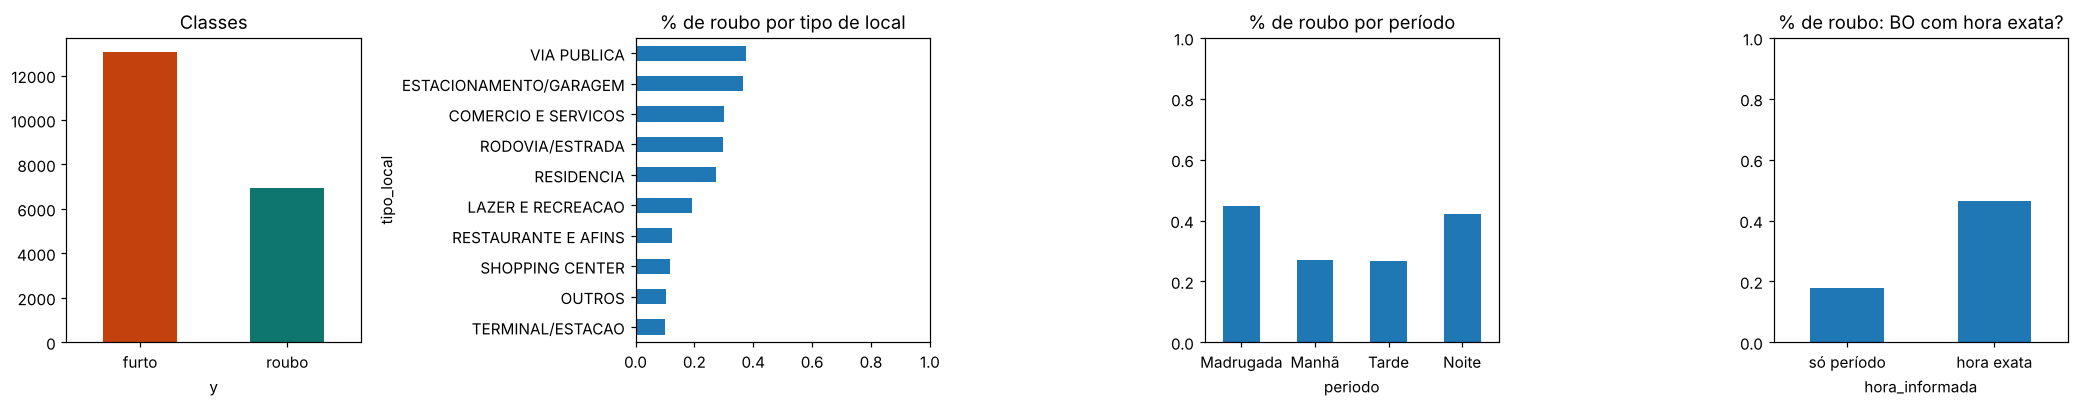

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
df["y"].map({0:"furto",1:"roubo"}).value_counts().plot.bar(ax=ax[0], rot=0, color=["#c2410c","#0f766e"]); ax[0].set_title("Classes")
(df.groupby("tipo_local")["y"].agg(["mean","size"]).query("size>=30")["mean"].sort_values()).plot.barh(ax=ax[1]); ax[1].set_title("% de roubo por tipo de local"); ax[1].set_xlim(0,1)
(df.groupby("periodo")["y"].mean().reindex(["Madrugada","Manhã","Tarde","Noite"])).plot.bar(ax=ax[2], rot=0); ax[2].set_title("% de roubo por período"); ax[2].set_ylim(0,1)
df.groupby("hora_informada")["y"].mean().rename({0:"só período",1:"hora exata"}).plot.bar(ax=ax[3], rot=0); ax[3].set_title("% de roubo: BO com hora exata?"); ax[3].set_ylim(0,1)
plt.tight_layout()

**Leitura da exploração.** As taxas de roubo variam entre tipos de local e períodos do dia — há sinal nos atributos escolhidos.
Se as classes estiverem desbalanceadas, a acurácia sozinha engana; por isso reportamos também **precision, recall e F1** da classe *roubo*
(classe positiva) e usamos divisão **estratificada**.

## 3. Atributos de entrada (e justificativa)

| Atributo | Tipo | Por quê | Tratamento |
|---|---|---|---|
| `bairro` | categórico (alta cardinalidade: ~1.900 grafias) | local do fato é o contexto geográfico mais direto | one-hot; bairros com < 30 ocorrências no **treino** → categoria "infrequente" |
| `tipo_local` | categórico | via pública, terminal, residência, comércio… alteram a natureza do crime | one-hot |
| `dia_semana` | categórico | rotina semanal (dia útil × fim de semana); derivado de `DATA_OCORRENCIA_BO` | one-hot |
| `periodo` | categórico | madrugada/manhã/tarde/noite, da hora exata ou de `DESCR_PERIODO` | one-hot |
| `hora_informada` | binário 0/1 | o BO traz hora exata ou só o período (furtos tendem a ser percebidos depois) | passa direto (já está em 0/1) |

**Escalonamento:** todas as entradas são one-hot ou binárias (0/1), já na mesma escala; não há variável contínua que exija padronização.
Ponto de atenção: `hora_informada` reflete *como o BO foi registrado*; a ablação na seção 7 mede o quanto o modelo depende dela.

**Excluídos de propósito:** a própria rubrica/natureza (revela o rótulo → *data leakage*), campos de conduta/tipo de crime que a definem, número do BO, vítima/dados pessoais,
`DESCR_CONDUTA`/`DESDOBRAMENTO`/`CIRCUNSTANCIA` (qualificam a natureza criminal), marca/tipo do objeto, latitude/longitude e logradouro (quase identificadores) e o município de registro.

## 4. Divisão dos dados e codificação
Divisão **estratificada 70/15/15** (treino/validação/teste). O pré-processador é ajustado (`fit`) **apenas no treino**.

In [4]:
Xtr, Xva, Xte, ytr, yva, yte = L.split_data(df)
pre = L.make_preprocessor().fit(Xtr)
Ptr, Pva, Pte = pre.transform(Xtr), pre.transform(Xva), pre.transform(Xte)
print(f"treino={len(ytr)}  validação={len(yva)}  teste={len(yte)}")
print(f"proporção de roubo -> treino {ytr.mean():.3f} | val {yva.mean():.3f} | teste {yte.mean():.3f}")
print("Entradas da rede após codificação:", Ptr.shape[1], "colunas")
print("Valores distintos nas colunas codificadas:", np.unique(Ptr))
base = max(yte.mean(), 1-yte.mean())
print(f"Baseline (sempre a classe majoritária): acurácia = {base:.3f}  -> a MLP precisa superar isso")

treino=14000  validação=3000  teste=3000
proporção de roubo -> treino 0.348 | val 0.348 | teste 0.348
Entradas da rede após codificação: 129 colunas
Valores distintos nas colunas codificadas: [0. 1.]
Baseline (sempre a classe majoritária): acurácia = 0.652  -> a MLP precisa superar isso


## 5. Implementação da MLP

**Arquitetura geral.** `Entrada (n atributos codificados) → [Dense + ativação] × k → Dense(1) + sigmoide`.

* **Camadas ocultas densas:** cada neurônio calcula `a = f(W·x + b)`. Empilhar camadas permite combinações não lineares dos atributos (ex.: "via pública *e* noite").
* **Ativação oculta – ReLU** (`max(0,z)`): barata, evita saturação do gradiente. Testamos também **tanh** (config. E).
* **Saída – 1 neurônio + sigmoide:** devolve P(roubo) ∈ (0,1) → classificação binária (limiar 0,5).
* **Perda – entropia cruzada binária (log-loss):** é a perda adequada para probabilidades e é convexa na saída.
* **Otimizador – Adam** (`lr=1e-3`): taxa adaptativa por parâmetro, converge bem sem muito ajuste. **Batch** = 128.
* **Regularização:** penalidade **L2** (`alpha`) + **early stopping** (para quando a perda de validação não melhora por 8 épocas e restaura os melhores pesos).

> Implementação com `sklearn.neural_network.MLPClassifier` treinado **uma época por vez** (`partial_fit`) para registrar as curvas de treino/validação.
> Código abaixo (também em `src/mlp_lib.py`):

In [5]:
print(inspect.getsource(L.train_mlp))

def train_mlp(cfg: dict, Xtr, ytr, Xva, yva, seed: int = SEED):
    """Treina 1 época por vez (partial_fit) para registrar curvas de perda/acurácia de treino e
    validação. Early stopping pela perda de validação (restaura os melhores pesos)."""
    mlp = MLPClassifier(hidden_layer_sizes=cfg["hidden"], activation=cfg["activation"], solver="adam",
                        alpha=cfg["alpha"], learning_rate_init=cfg["lr"], batch_size=BATCH,
                        shuffle=True, random_state=seed)
    hist = {k: [] for k in ("loss", "val_loss", "acc", "val_acc")}
    best, best_w, wait = np.inf, None, 0
    for epoch in range(MAX_EPOCHS):
        mlp.partial_fit(Xtr, ytr, classes=[0, 1])
        p_tr, p_va = mlp.predict_proba(Xtr)[:, 1], mlp.predict_proba(Xva)[:, 1]
        hist["loss"].append(log_loss(ytr, p_tr)); hist["val_loss"].append(log_loss(yva, p_va))
        hist["acc"].append(accuracy_score(ytr, p_tr > .5)); hist["val_acc"].append(accuracy_score(yva, p_va > .5))
        if hist["

## 6. Experimentos com arquiteturas
Variamos **profundidade, largura, ativação e regularização** (uma mudança principal por comparação):

| Config. | Camadas ocultas | Ativação | L2 (alpha) | O que testa |
|---|---|---|---|---|
| A | 16 | ReLU | 1e-4 | linha de base pequena (subajuste?) |
| B | 64-32 | ReLU | 1e-4 | mais capacidade |
| C | 128-64-32 | ReLU | 1e-5 | capacidade alta, pouca regularização (risco de overfitting) |
| D | 128-64-32 | ReLU | 1e-1 | mesma rede de C com **L2 forte** — efeito da regularização |
| E | 64-32 | tanh | 1e-4 | mesma rede de B com outra **ativação** |

In [6]:
results = L.run_experiments(Ptr, ytr, Pva, yva)
tab = L.comparison_table(results)
print(tab.round(4).to_string())

                           parametros  epocas  melhor_epoca  acc_treino  acc_val  precision_val  recall_val  f1_val  loss_val
modelo                                                                                                                       
A_simples (16)                   2080      28            20      0.7370   0.7383         0.6434      0.5565  0.5968    0.5284
B_media (64-32)                 10336      13             5      0.7464   0.7337         0.6794      0.4444  0.5373    0.5324
C_profunda (128-64-32)          26784       9             1      0.7328   0.7310         0.6804      0.4282  0.5256    0.5407
D_profunda_L2 (128-64-32)       26784      15             7      0.7424   0.7347         0.7296      0.3774  0.4975    0.5388
E_tanh (64-32)                  10336      25            17      0.7408   0.7340         0.6847      0.4368  0.5333    0.5292


## 7. Avaliação comparativa e seleção (somente validação)

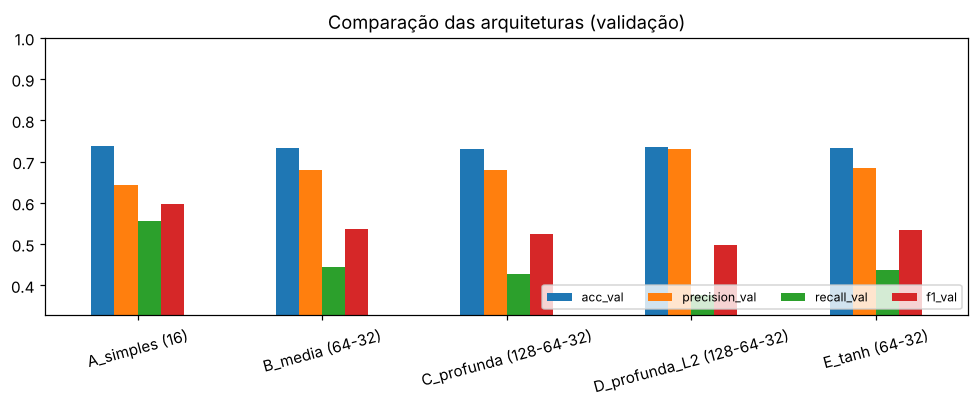

In [7]:
L.plot_comparison(tab);

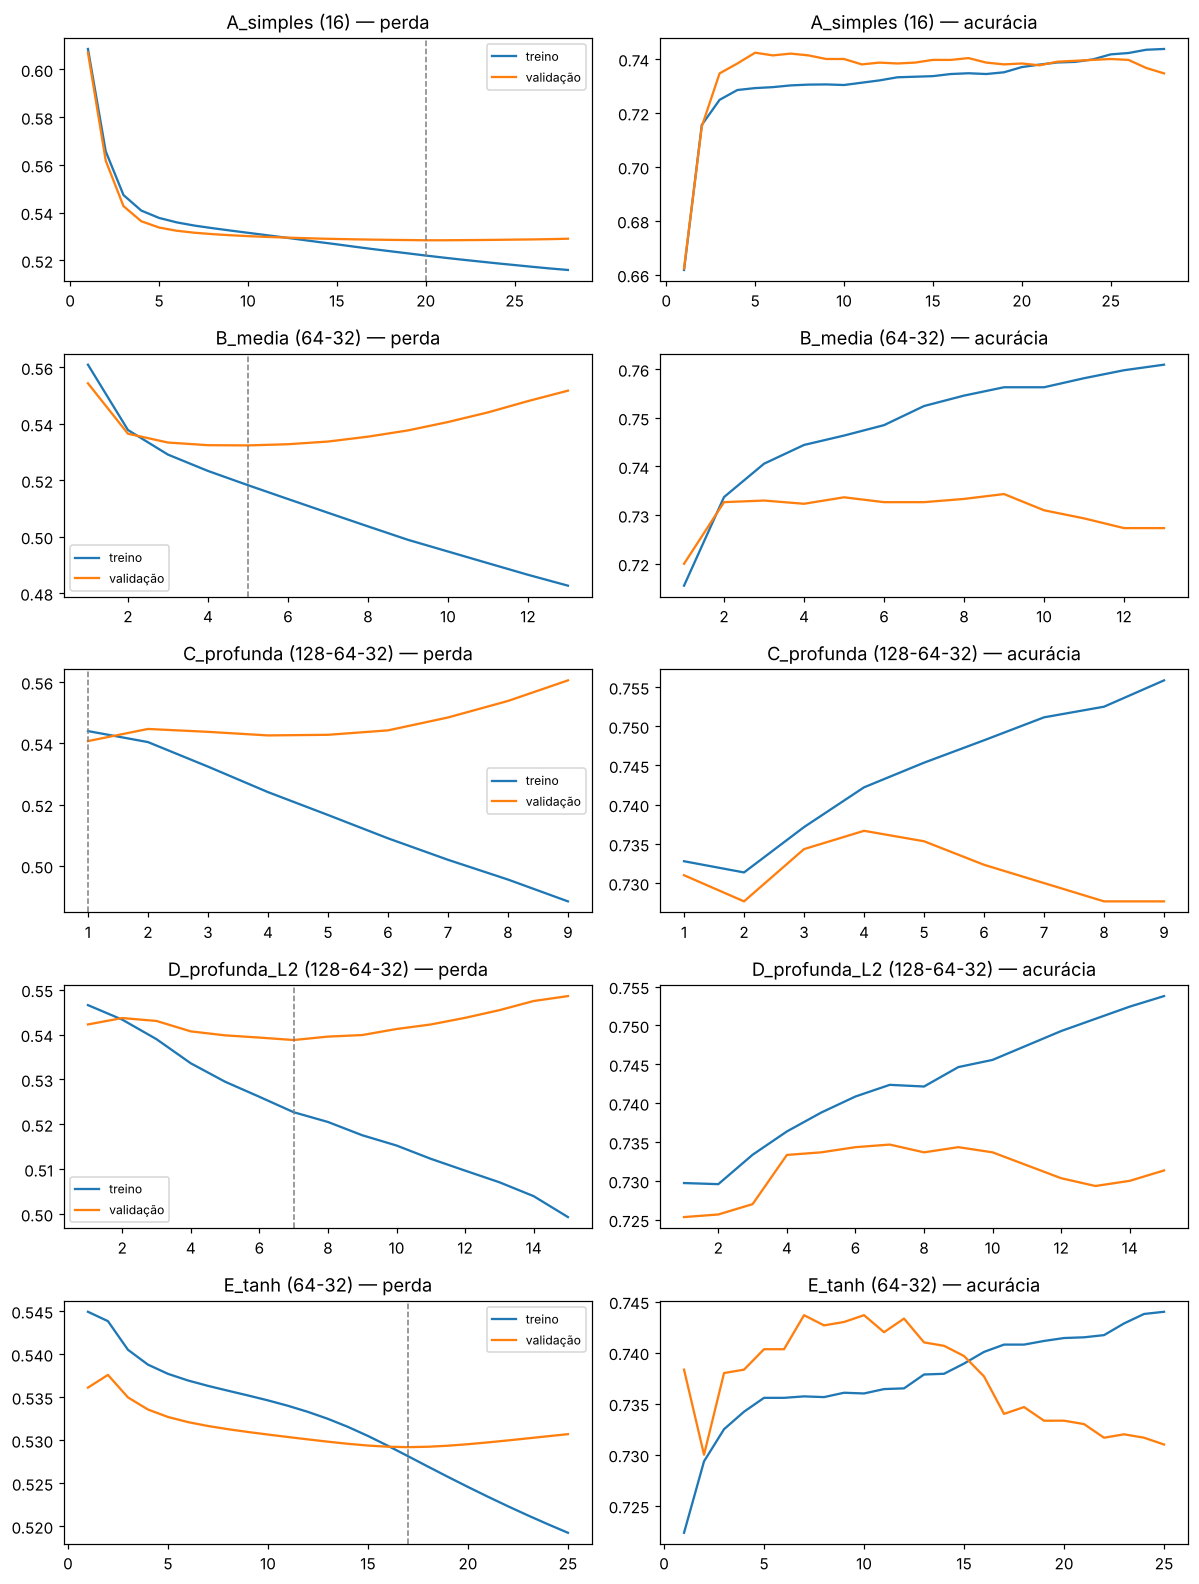

In [8]:
fig, axs = plt.subplots(len(results), 2, figsize=(11, 2.9*len(results)), sharex=False)
for r, (name, res) in zip(axs, results.items()):
    h = res["hist"]; ep = np.arange(1, len(h["loss"])+1)
    r[0].plot(ep, h["loss"], label="treino"); r[0].plot(ep, h["val_loss"], label="validação"); r[0].axvline(h["best_epoch"], ls="--", c="gray", lw=1)
    r[0].set_title(f"{name} — perda"); r[0].legend(fontsize=8)
    r[1].plot(ep, h["acc"], label="treino"); r[1].plot(ep, h["val_acc"], label="validação"); r[1].set_title(f"{name} — acurácia")
plt.tight_layout()

In [9]:
best = L.select_best(tab)
print("Critério: maior F1 na validação; empate técnico (<= 0,5 p.p.) -> menos parâmetros.")
print("Arquitetura selecionada:", best)
print("\nDiagnóstico automático (treino vs. validação):")
for name, res in results.items():
    gap = res["train"]["accuracy"] - res["val"]["accuracy"]
    h = res["hist"]; ruido = h["val_loss"][-1] - min(h["val_loss"])
    estado = ("possível OVERFITTING" if gap > 0.03 or ruido > 0.02 else
              "possível UNDERFITTING" if res["train"]["accuracy"] < 0.65 else "bom ajuste")
    print(f"  {name:28s} gap acc(treino-val)={gap:+.3f} | perda val subiu {ruido:+.3f} após o mínimo (época {h['best_epoch']}/{h['epochs_run']}) -> {estado}")

Critério: maior F1 na validação; empate técnico (<= 0,5 p.p.) -> menos parâmetros.
Arquitetura selecionada: A_simples (16)

Diagnóstico automático (treino vs. validação):
  A_simples (16)               gap acc(treino-val)=-0.001 | perda val subiu +0.001 após o mínimo (época 20/28) -> bom ajuste
  B_media (64-32)              gap acc(treino-val)=+0.013 | perda val subiu +0.019 após o mínimo (época 5/13) -> bom ajuste
  C_profunda (128-64-32)       gap acc(treino-val)=+0.002 | perda val subiu +0.020 após o mínimo (época 1/9) -> bom ajuste
  D_profunda_L2 (128-64-32)    gap acc(treino-val)=+0.008 | perda val subiu +0.010 após o mínimo (época 7/15) -> bom ajuste
  E_tanh (64-32)               gap acc(treino-val)=+0.007 | perda val subiu +0.002 após o mínimo (época 17/25) -> bom ajuste


**Como ler o diagnóstico.**
*Overfitting*: acurácia/perda de treino continuam melhorando enquanto a de validação piora (a distância entre as curvas aumenta) — o early stopping interrompe esse ponto e restaura os melhores pesos.
*Underfitting*: treino e validação ruins e próximos. Se as arquiteturas maiores (C, D) **não superam** a pequena (A) de forma relevante, a limitação está nos **atributos** (informação disponível), não na capacidade da rede.

### Ablação: o quanto o modelo depende de `hora_informada`?
Treinamos a arquitetura selecionada **sem** esse atributo e comparamos na validação.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
pre2 = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), L.CAT)]).fit(Xtr)
m2, h2 = L.train_mlp(results[best]["cfg"], pre2.transform(Xtr), ytr, pre2.transform(Xva), yva)
abl = L.metrics(yva, m2.predict(pre2.transform(Xva)))
com = results[best]["val"]
print(pd.DataFrame({"com hora_informada": com, "sem hora_informada": abl}).T.round(4).to_string())
print(f"Baseline (classe majoritária) na validação: {max(yva.mean(), 1-yva.mean()):.3f}")

                    accuracy  precision  recall      f1
com hora_informada    0.7383     0.6434  0.5565  0.5968
sem hora_informada    0.7160     0.6311  0.4425  0.5203
Baseline (classe majoritária) na validação: 0.652


## 8. Avaliação final no conjunto de teste (usado uma única vez)

In [11]:
from sklearn.metrics import classification_report
m = results[best]["model"]; pred_te = m.predict(Pte)
print("Métricas no TESTE:", {k: round(v,4) for k,v in L.metrics(yte, pred_te).items()}, f"| baseline acc = {base:.4f}")
print(); print(classification_report(yte, pred_te, target_names=L.CLASSES, digits=3))

Métricas no TESTE: {'accuracy': 0.7363, 'precision': 0.6449, 'recall': 0.5393, 'f1': 0.5874} | baseline acc = 0.6520

              precision    recall  f1-score   support

       furto      0.774     0.842     0.806      1956
       roubo      0.645     0.539     0.587      1044

    accuracy                          0.736      3000
   macro avg      0.709     0.690     0.697      3000
weighted avg      0.729     0.736     0.730      3000



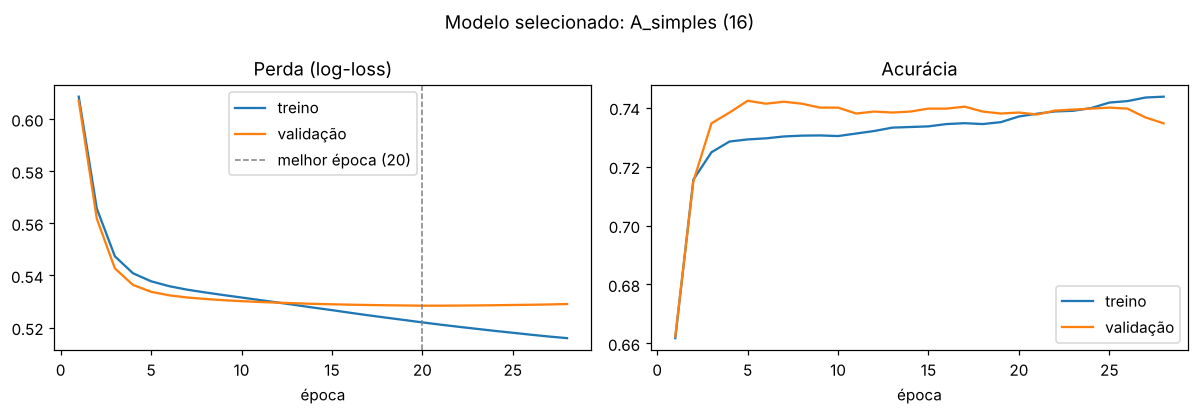

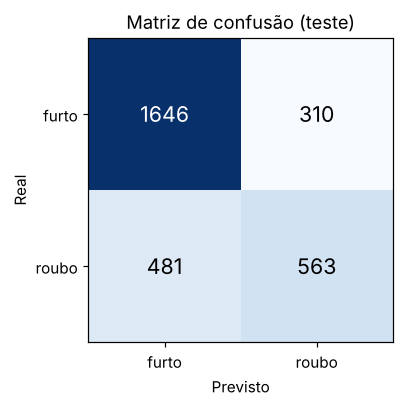

In [12]:
L.plot_curves(results[best]["hist"], f"Modelo selecionado: {best}"); L.plot_confusion(yte, pred_te, "Matriz de confusão (teste)");

## 9. Exportação do modelo para a aplicação web

In [13]:
options = L.form_options(pre, Xtr)
(ROOT/"models").mkdir(exist_ok=True)
L.save_bundle(ROOT/"models/modelo_mlp.joblib", pre, m, best, results[best]["cfg"], options, dict(synthetic=SINTETICO, n_features_in=int(Ptr.shape[1])))
print("Salvo em models/modelo_mlp.joblib | opções do formulário:", {k: (len(v) if k!='hora' else v) for k,v in options.items()})

Salvo em models/modelo_mlp.joblib | opções do formulário: {'bairro': 105, 'tipo_local': 10, 'dia_semana': 7, 'periodo': 4}


## 10. Conclusões e limitações
* A arquitetura escolhida e as métricas estão acima; **a escolha foi feita na validação** e o teste foi usado só no final.
* **A acurácia deve ser lida contra o baseline** de sempre prever a classe majoritária (impresso nas seções 4 e 8). Como roubo é a classe minoritária, **recall e F1 de roubo** são as métricas mais informativas.
* Os atributos disponíveis (local, bairro, dia e período) carregam informação limitada sobre a natureza do crime; arquiteturas maiores (C, D) não superaram a pequena de forma relevante, indicando que o limite está na **informação dos atributos**, não na capacidade da rede.
* Com limiar 0,5 o modelo é conservador ao apontar roubo (precision > recall); o limiar pode ser ajustado conforme o custo de cada tipo de erro.
* **Limitações:** (i) boletins refletem só o que foi registrado (subnotificação); (ii) rubrica depende da classificação do registro policial; (iii) possíveis vieses geográficos/sociais nos dados — o modelo **não** deve ser usado para policiamento preditivo nem para julgar pessoas ou locais; (iv) bairros raros são agrupados.
* **Trabalhos futuros:** mais anos de dados, validação temporal (treinar em meses anteriores, testar nos posteriores), calibração de probabilidades, ajuste de limiar conforme o custo de cada tipo de erro.
* **Uso de IA generativa:** assistente de IA apoiou a estruturação do código e da documentação; a equipe revisou, executou e é capaz de explicar cada etapa.